# Exploratory Data Analysis (EDA)

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Exploratory Data Analysis (EDA) is an essential step in the data science workflow. It provides a comprehensive understanding of the processed dataset by examining its structure, distributions, relationships, and potential anomalies before statistical analysis and predictive modeling.

The objectives of this notebook are to:

- Load the processed applicant-level dataset.
- Examine the overall structure of the data.
- Analyze the distribution of the target variable.
- Explore numerical and categorical features.
- Identify missing values, outliers, and skewed distributions.
- Investigate relationships between features and credit default.
- Perform correlation analysis.
- Summarize key business insights that will guide feature engineering and machine learning model development.

# Import Required Libraries

The following libraries are used for data manipulation, visualization, and statistical analysis throughout this notebook.

In [1]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Plot settings
plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

RANDOM_STATE = 42

# Load the Processed Dataset

The applicant-level dataset generated during the preprocessing stage is loaded for exploratory analysis.

In [2]:
# ============================================================
# Load Processed Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

merged_df = pd.read_csv(DATA_DIR / "credit_risk_processed.csv")

print("Dataset loaded successfully.")

print(f"Rows    : {merged_df.shape[0]:,}")
print(f"Columns : {merged_df.shape[1]:,}")

Dataset loaded successfully.
Rows    : 307,511
Columns : 362


# Display Sample Records

Before performing any analysis, the first few observations of the processed dataset are examined to verify that the data has been loaded correctly.

In [3]:
# Display first five observations

merged_df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,LANDAREA_AVG,LIVINGAREA_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,ELEVATORS_MODE,ENTRANCES_MODE,FLOORSMAX_MODE,LANDAREA_MODE,LIVINGAREA_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,LANDAREA_MEDI,LIVINGAREA_MEDI,NONLIVINGAREA_MEDI,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,BUREAU_DAYS_CREDIT_MEAN,BUREAU_DAYS_CREDIT_MAX,BUREAU_DAYS_CREDIT_MIN,BUREAU_DAYS_CREDIT_SUM,BUREAU_CREDIT_DAY_OVERDUE_MEAN,BUREAU_CREDIT_DAY_OVERDUE_MAX,BUREAU_CREDIT_DAY_OVERDUE_MIN,BUREAU_CREDIT_DAY_OVERDUE_SUM,BUREAU_DAYS_CREDIT_ENDDATE_MEAN,BUREAU_DAYS_CREDIT_ENDDATE_MAX,BUREAU_DAYS_CREDIT_ENDDATE_MIN,BUREAU_DAYS_CREDIT_ENDDATE_SUM,BUREAU_DAYS_ENDDATE_FACT_MEAN,BUREAU_DAYS_ENDDATE_FACT_MAX,BUREAU_DAYS_ENDDATE_FACT_MIN,BUREAU_DAYS_ENDDATE_FACT_SUM,BUREAU_AMT_CREDIT_MAX_OVERDUE_MEAN,BUREAU_AMT_CREDIT_MAX_OVERDUE_MAX,BUREAU_AMT_CREDIT_MAX_OVERDUE_MIN,BUREAU_AMT_CREDIT_MAX_OVERDUE_SUM,BUREAU_CNT_CREDIT_PROLONG_MEAN,BUREAU_CNT_CREDIT_PROLONG_MAX,BUREAU_CNT_CREDIT_PROLONG_MIN,BUREAU_CNT_CREDIT_PROLONG_SUM,BUREAU_AMT_CREDIT_SUM_MEAN,BUREAU_AMT_CREDIT_SUM_MAX,BUREAU_AMT_CREDIT_SUM_MIN,BUREAU_AMT_CREDIT_SUM_SUM,BUREAU_AMT_CREDIT_SUM_DEBT_MEAN,BUREAU_AMT_CREDIT_SUM_DEBT_MAX,BUREAU_AMT_CREDIT_SUM_DEBT_MIN,BUREAU_AMT_CREDIT_SUM_DEBT_SUM,BUREAU_AMT_CREDIT_SUM_LIMIT_MEAN,BUREAU_AMT_CREDIT_SUM_LIMIT_MAX,BUREAU_AMT_CREDIT_SUM_LIMIT_MIN,BUREAU_AMT_CREDIT_SUM_LIMIT_SUM,BUREAU_AMT_CREDIT_SUM_OVERDUE_MEAN,BUREAU_AMT_CREDIT_SUM_OVERDUE_MAX,BUREAU_AMT_CREDIT_SUM_OVERDUE_MIN,BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM,BUREAU_DAYS_CREDIT_UPDATE_MEAN,BUREAU_DAYS_CREDIT_UPDATE_MAX,BUREAU_DAYS_CREDIT_UPDATE_MIN,BUREAU_DAYS_CREDIT_UPDATE_SUM,BUREAU_AMT_ANNUITY_MEAN,BUREAU_AMT_ANNUITY_MAX,BUREAU_AMT_ANNUITY_MIN,BUREAU_AMT_ANNUITY_SUM,BUREAU_BB_MONTHS_BALANCE_MIN_MEAN,BUREAU_BB_MONTHS_BALANCE_MIN_MAX,BUREAU_BB_MONTHS_BALANCE_MIN_MIN,BUREAU_BB_MONTHS_BALANCE_MIN_SUM,BUREAU_BB_MONTHS_BALANCE_MAX_MEAN,BUREAU_BB_MONTHS_BALANCE_MAX_MAX,BUREAU_BB_MONTHS_BALANCE_MAX_MIN,BUREAU_BB_MONTHS_BALANCE_MAX_SUM,BUREAU_BB_MONTHS_BALANCE_MEAN_MEAN,BUREAU_BB_MONTHS_BALANCE_MEAN_MAX,BUREAU_BB_MONTHS_BALANCE_MEAN_MIN,BUREAU_BB_MONTHS_BALANCE_MEAN_SUM,BUREAU_BB_MONTHS_BALANCE_COUNT_MEAN,BUREAU_BB_MONTHS_BALANCE_COUNT_MAX,BUREAU_BB_MONTHS_BALANCE_COUNT_MIN,BUREAU_BB_MONTHS_BALANCE_COUNT_SUM,PREV_AMT_ANNUITY_MEAN,PREV_AMT_ANNUITY_MAX,PREV_AMT_ANNUITY_MIN,PREV_AMT_ANNUITY_SUM,PREV_AMT_APPLICATION_MEAN,PREV_AMT_APPLICATI

# Dataset Overview

The overall structure of the dataset is examined by reviewing:

- Number of rows and columns
- Data types
- Memory usage
- Missing values
- Number of numerical and categorical variables

This provides an initial understanding of the processed dataset.

In [4]:
merged_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 362 entries, SK_ID_CURR to POS_SK_DPD_DEF_SUM
dtypes: float64(306), int64(41), str(15)
memory usage: 890.4 MB


# Dataset Summary

The dimensions of the dataset and the distribution of numerical and categorical variables are summarized below.

In [5]:
summary = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Numerical Features",
        "Categorical Features"
    ],
    "Value": [
        merged_df.shape[0],
        merged_df.shape[1],
        merged_df.select_dtypes(include=np.number).shape[1],
        merged_df.select_dtypes(exclude=np.number).shape[1]
    ]
})

summary

,Metric,Value
0,Rows,307511
1,Columns,362
2,Numerical Features,347
3,Categorical Features,15


# Dataset Overview and Initial Observations

The processed dataset consists of **307,511 applicants**, with each row representing a unique loan application. After aggregating the historical transactional datasets and merging them with the primary application data, the final dataset contains **362 features**.

The feature composition is as follows:

| Metric | Value |
|---------|------:|
| Number of Records | 307,511 |
| Number of Features | 362 |
| Numerical Features | 347 |
| Categorical Features | 15 |

### Initial Observations

- The preprocessing pipeline successfully transformed multiple transactional datasets into a single applicant-level dataset.
- Numerical variables account for the majority of the dataset (347 features), reflecting extensive financial and historical credit information.
- Only 15 categorical variables remain, primarily representing demographic and application-related characteristics.
- The dataset occupies approximately **849 MB** of memory, indicating that subsequent analyses should focus on efficient computations and selective visualizations.
- The merged dataset is now suitable for exploratory analysis, hypothesis testing, feature engineering, dimensionality reduction, and predictive modeling.

# Missing Value Verification

Although missing values were addressed during preprocessing, new missing values may appear after merging the aggregated datasets.

These missing values are expected because some applicants do not have historical records in external datasets such as Bureau, Previous Applications, Credit Card Balance, Installments Payments, or POS Cash Balance.

The following analysis quantifies the remaining missing values in the merged dataset.

In [6]:
# ============================================================
# Missing Value Summary
# ============================================================

missing_summary = (
    merged_df.isnull()
             .sum()
             .reset_index()
)

missing_summary.columns = ["Feature", "Missing Values"]

missing_summary["Missing Percentage"] = (
    missing_summary["Missing Values"] / len(merged_df) * 100
)

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary.head(20)

,Feature,Missing Values,Missing Percentage
339,CC_SK_DPD_DEF_MAX,220606,71.739222
338,CC_SK_DPD_DEF_MEAN,220606,71.739222
340,CC_SK_DPD_DEF_MIN,220606,71.739222
333,CC_CNT_INSTALMENT_MATURE_CUM_SUM,220606,71.739222
334,CC_SK_DPD_MEAN,220606,71.739222
335,CC_SK_DPD_MAX,220606,71.739222
336,CC_SK_DPD_MIN,220606,71.739222
337,CC_SK_DPD_SUM,220606,71.739222
321,CC_CNT_DRAWINGS_CURRENT_SUM,220606,71.739222
320,CC_CNT_DRAWINGS_CURRENT_MIN,220606,71.739222


# Overall Missing Value Statistics

To assess the completeness of the merged dataset, overall missing value statistics are calculated.

This summary reports:

- Total missing values
- Percentage of missing values
- Number of features containing missing values
- Number of complete features

In [7]:
# ============================================================
# Overall Missing Value Statistics
# ============================================================

total_cells = merged_df.shape[0] * merged_df.shape[1]

total_missing = merged_df.isnull().sum().sum()

missing_percentage = (total_missing / total_cells) * 100

features_with_missing = (merged_df.isnull().sum() > 0).sum()

complete_features = merged_df.shape[1] - features_with_missing

summary_missing = pd.DataFrame({
    "Metric": [
        "Total Missing Values",
        "Missing Percentage (%)",
        "Features with Missing Values",
        "Complete Features"
    ],
    "Value": [
        total_missing,
        round(missing_percentage, 2),
        features_with_missing,
        complete_features
    ]
})

summary_missing

,Metric,Value
0,Total Missing Values,24381924.0
1,Missing Percentage (%),21.9
2,Features with Missing Values,256.0
3,Complete Features,106.0


# Interpretation of Missing Values

The merged dataset contains **24,381,924 missing values**, representing approximately **21.9%** of all data entries. These missing values are distributed across **256 features**, while **106 features** are complete.

The majority of missing values occur in aggregated variables derived from historical transactional datasets, particularly the Credit Card Balance (`CC_*`) features.

### Key Observations

- Applicants without historical credit card accounts have missing values for all aggregated credit card features.
- Similar structural missing values may occur in Bureau, Previous Application, Installments, and POS Cash features when no historical records exist.
- These missing values indicate the **absence of historical financial activity** rather than poor data quality.
- Therefore, they should be interpreted as structural missing values introduced during the left-join aggregation process.

The treatment of these structural missing values will be addressed during the **Feature Engineering and PCA** stage, where appropriate imputation strategies will be applied based on business relevance and modeling requirements.

# Descriptive Statistics

Descriptive statistics provide a summary of the central tendency, variability, and distribution of the numerical variables in the dataset.

The analysis includes:

- Count of observations
- Mean
- Standard deviation
- Minimum and maximum values
- Quartiles (25%, 50%, and 75%)

These statistics provide an initial understanding of the financial and demographic characteristics of loan applicants and help identify potential outliers and unusual value ranges.

In [8]:
# ============================================================
# Descriptive Statistics for Numerical Features
# ============================================================

merged_df.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,4.562550e+05
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.000000e+00
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,1.900000e+01
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,1.170000e+08
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4.050000e+06
...,...,...,...,...,...,...,...,...
POS_SK_DPD_SUM,289444.0,351.386075,5678.136399,0.0,0.0,0.0,0.0,2.674520e+05
POS_SK_DPD_DEF_MEAN,289444.0,0.214863,12.926305,0.0,0.0,0.0,0.0,1.740554e+03
POS_SK_DPD_DEF_MAX,289444.0,1.468830,30.609586,0.0,0.0,0.0,0.0,3.373000e+03
POS_SK_DPD_DEF_MIN,289444.0,0.001054,0.405600,0.0,0.0,0.0,0.0,1.760000e+02


# Summary Statistics of Key Financial Variables

Instead of examining all numerical variables simultaneously, the analysis focuses on the primary financial and demographic variables that directly influence credit risk assessment.

The selected variables include:

- TARGET
- AMT_INCOME_TOTAL
- AMT_CREDIT
- AMT_ANNUITY
- AMT_GOODS_PRICE
- DAYS_BIRTH
- DAYS_EMPLOYED

These variables represent the applicant's financial capacity, requested loan characteristics, and demographic profile.

In [9]:
# ============================================================
# Summary Statistics for Key Variables
# ============================================================

key_features = [
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

merged_df[key_features].describe().T

,count,mean,std,min,25%,50%,75%,max
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
AMT_ANNUITY,307511.0,27108.487841,14493.461065,1615.5,16524.0,24903.0,34596.0,258025.5
AMT_GOODS_PRICE,307511.0,538316.294367,369288.982246,40500.0,238500.0,450000.0,679500.0,4050000.0
DAYS_BIRTH,307511.0,-16036.995067,4363.988632,-25229.0,-19682.0,-15750.0,-12413.0,-7489.0
DAYS_EMPLOYED,307511.0,63815.045904,141275.766519,-17912.0,-2760.0,-1213.0,-289.0,365243.0


# Distribution of the Target Variable

The target variable (`TARGET`) indicates whether an applicant experienced payment difficulties.

- **TARGET = 0:** Applicant did not default.
- **TARGET = 1:** Applicant defaulted.

Understanding the class distribution is essential because an imbalanced dataset may influence the performance of machine learning models and evaluation metrics.

In [10]:
# ============================================================
# Target Variable Distribution
# ============================================================

target_counts = merged_df["TARGET"].value_counts().sort_index()

target_percent = (
    merged_df["TARGET"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage (%)": target_percent.round(2)
})

target_summary.index = ["No Default (0)", "Default (1)"]

target_summary

,Count,Percentage (%)
No Default (0),282686,91.93
Default (1),24825,8.07


# Visualization of Target Variable

A count plot is used to visualize the number of applicants in each target class.

The plot helps identify whether the dataset is balanced or imbalanced, which is an important consideration when selecting machine learning algorithms and evaluation metrics.

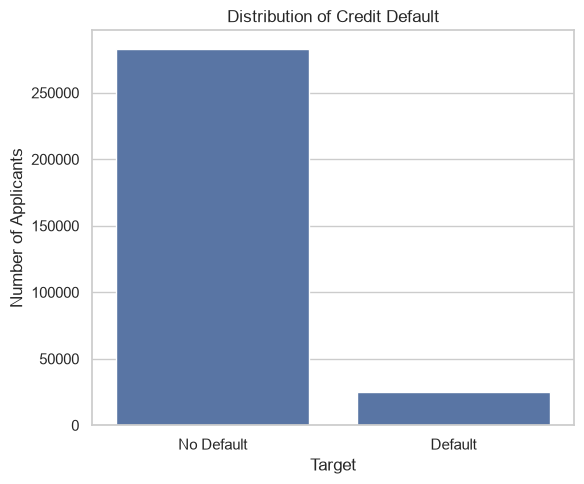

In [11]:
# ============================================================
# Target Variable Count Plot
# ============================================================

plt.figure(figsize=(6, 5))

sns.countplot(
    data=merged_df,
    x="TARGET"
)

plt.title("Distribution of Credit Default")
plt.xlabel("Target")
plt.ylabel("Number of Applicants")

plt.xticks(
    [0, 1],
    ["No Default", "Default"]
)

plt.tight_layout()
plt.show()

# Distribution of Key Numerical Features

Understanding the distribution of numerical variables helps identify:

- Central tendency and spread
- Skewness
- Potential outliers
- Data concentration

The following variables are selected because of their importance in credit risk assessment:

- Annual Income (`AMT_INCOME_TOTAL`)
- Loan Amount (`AMT_CREDIT`)
- Loan Annuity (`AMT_ANNUITY`)
- Goods Price (`AMT_GOODS_PRICE`)
- Applicant Age (`DAYS_BIRTH`)
- Employment Duration (`DAYS_EMPLOYED`)

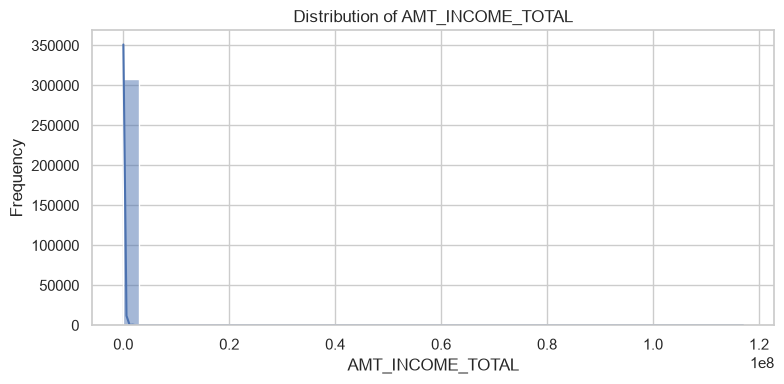

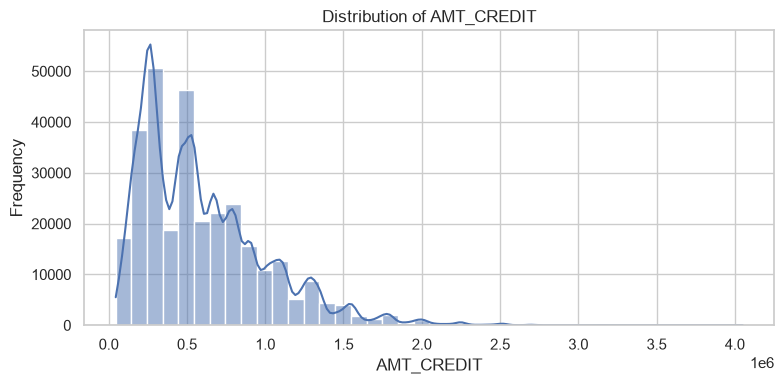

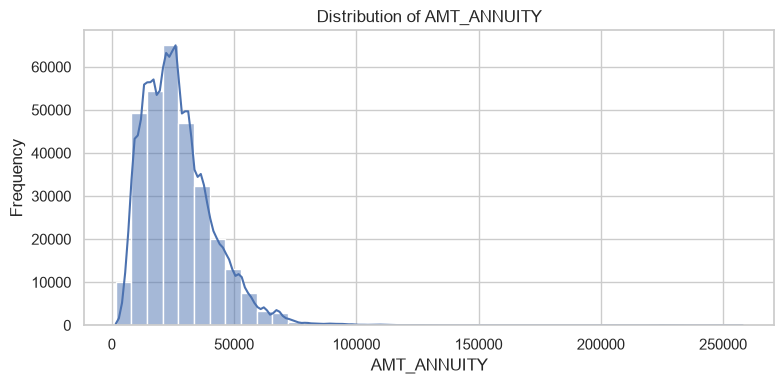

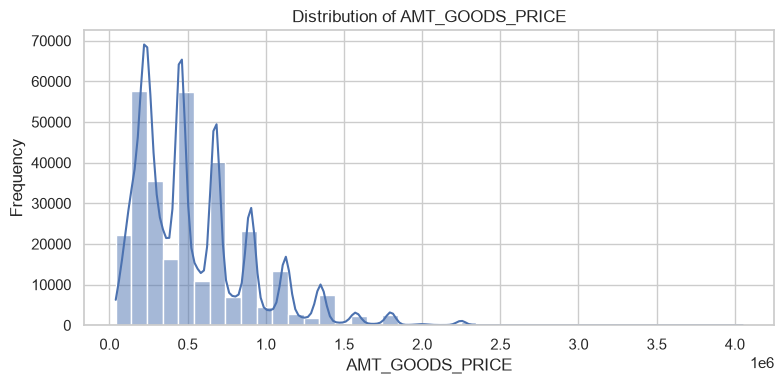

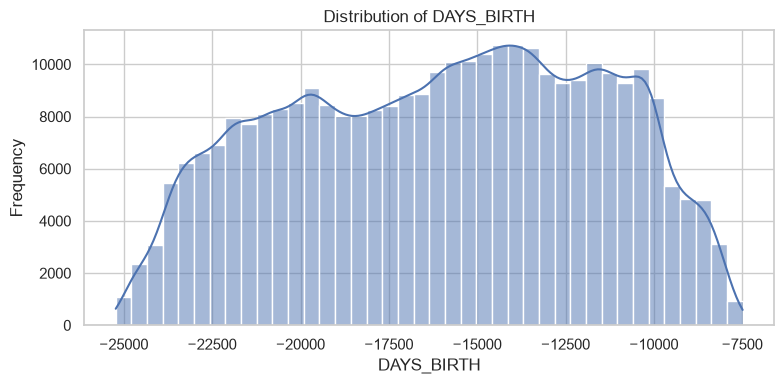

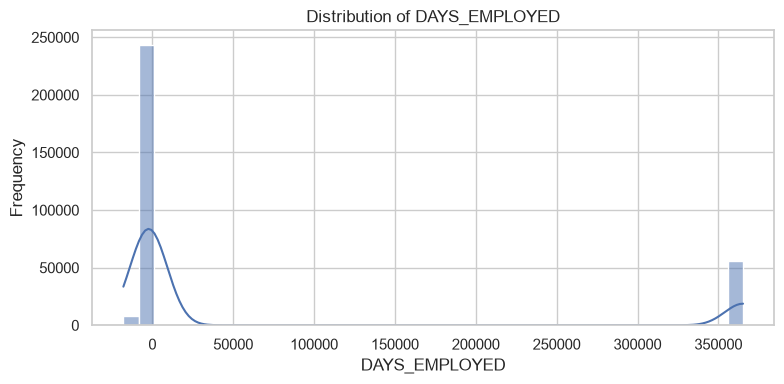

In [12]:
# ============================================================
# Distribution of Key Numerical Features
# ============================================================

key_numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED"
]

for feature in key_numeric_features:

    plt.figure(figsize=(8,4))

    sns.histplot(
        merged_df[feature],
        bins=40,
        kde=True
    )

    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

# Outlier Detection

Financial datasets often contain extreme observations that may influence statistical analysis and predictive modeling.

Boxplots are used to visualize:

- Median
- Interquartile Range (IQR)
- Potential outliers

The analysis focuses on major financial variables commonly used in credit risk assessment.

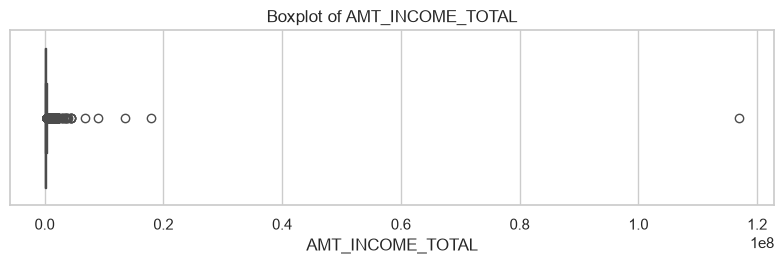

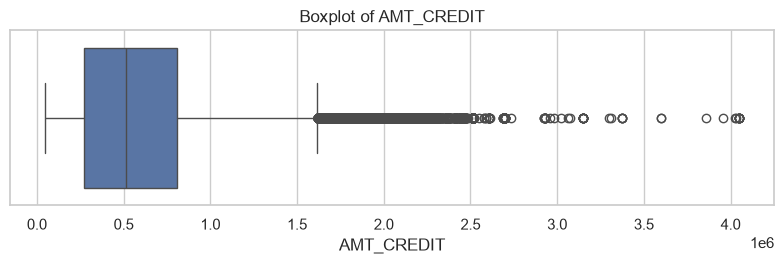

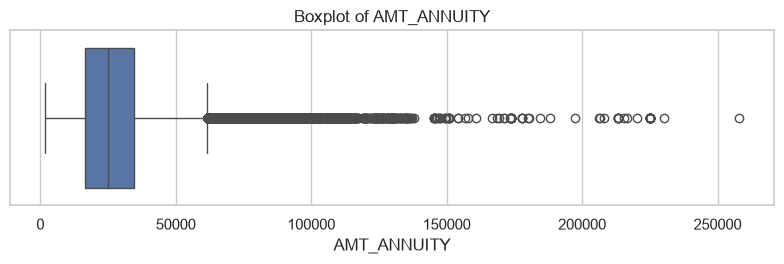

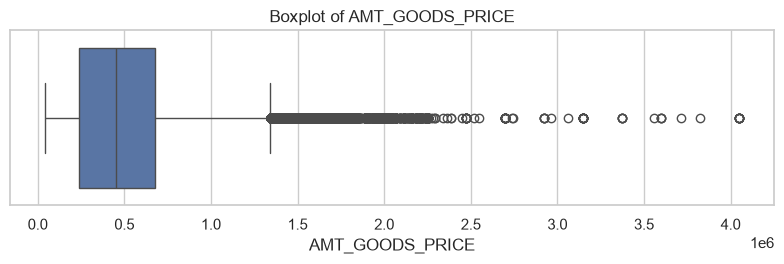

In [13]:
# ============================================================
# Boxplots for Key Financial Variables
# ============================================================

financial_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

for feature in financial_features:

    plt.figure(figsize=(8,2.8))

    sns.boxplot(
        x=merged_df[feature]
    )

    plt.title(f"Boxplot of {feature}")

    plt.tight_layout()
    plt.show()

# Skewness Analysis

Many financial variables exhibit skewed distributions due to the presence of high-income applicants or large loan amounts.

The skewness coefficient is calculated to identify variables that may require transformation during the Feature Engineering stage.

General interpretation:

- Skewness ≈ 0 → Approximately symmetric
- Skewness > 1 → Highly positively skewed
- Skewness < -1 → Highly negatively skewed

In [14]:
# ============================================================
# Skewness of Numerical Features
# ============================================================

skewness = (
    merged_df
    .select_dtypes(include="number")
    .skew()
    .sort_values(key=abs, ascending=False)
)

skewness.head(20).to_frame("Skewness")

,Skewness
FLAG_MOBIL,-554.536744
BUREAU_AMT_ANNUITY_MIN,456.089602
POS_SK_DPD_DEF_MIN,393.426076
FLAG_DOCUMENT_12,392.114779
AMT_INCOME_TOTAL,391.559654
PREV_SELLERPLACE_AREA_MIN,374.351117
BUREAU_AMT_CREDIT_SUM_OVERDUE_MIN,364.549014
PREV_SELLERPLACE_AREA_MEAN,357.969302
BUREAU_AMT_CREDIT_MAX_OVERDUE_MAX,318.257399
BUREAU_AMT_CREDIT_MAX_OVERDUE_SUM,314.557074


# Interpretation of Numerical Feature Analysis

The distribution plots, boxplots, and skewness analysis provide valuable insights into the numerical characteristics of the dataset.

These observations help identify variables that may require scaling, transformation, or special treatment before applying machine learning algorithms.

Potential preprocessing steps such as logarithmic transformation, robust scaling, or normalization will be considered during the Feature Engineering notebook.

# Categorical Feature Analysis

Categorical variables describe the demographic, socioeconomic, and application characteristics of loan applicants.

This section aims to:

- Examine the distribution of categorical variables.
- Identify dominant applicant groups.
- Compare applicant characteristics across categories.
- Investigate the relationship between categorical variables and credit default.

Understanding these characteristics provides valuable business insights into factors that may influence repayment behavior.

In [15]:
# ============================================================
# Identify Categorical Features
# ============================================================

categorical_features = merged_df.select_dtypes(include=["object"]).columns.tolist()

print(f"Number of categorical features: {len(categorical_features)}\n")

categorical_features

Number of categorical features: 15



['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

# Frequency Distribution of Categorical Variables

The frequency distribution of each categorical feature is examined to understand the composition of the applicant population.

For each variable, the five most frequent categories are displayed.

In [16]:
# ============================================================
# Frequency Distribution
# ============================================================

for feature in categorical_features:

    print("=" * 70)
    print(feature)

    display(
        merged_df[feature]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Count")
    )

NAME_CONTRACT_TYPE


,Count
NAME_CONTRACT_TYPE,
Cash loans,278232
Revolving loans,29279


CODE_GENDER


,Count
CODE_GENDER,
F,202448
M,105059
XNA,4


FLAG_OWN_CAR


,Count
FLAG_OWN_CAR,
N,202924
Y,104587


... (20 outputs left out)

WALLSMATERIAL_MODE


,Count
WALLSMATERIAL_MODE,
Panel,222381
"Stone, brick",64815
Block,9253
Wooden,5362
Mixed,2296
Monolithic,1779
Others,1625


EMERGENCYSTATE_MODE


,Count
EMERGENCYSTATE_MODE,
No,305183
Yes,2328


# Distribution of Major Applicant Characteristics

The following variables represent important demographic and socioeconomic characteristics commonly used in credit risk assessment:

- Gender
- Contract Type
- Income Type
- Education Level
- Family Status
- Housing Type

Bar charts are used to visualize the distribution of applicants across these categories.

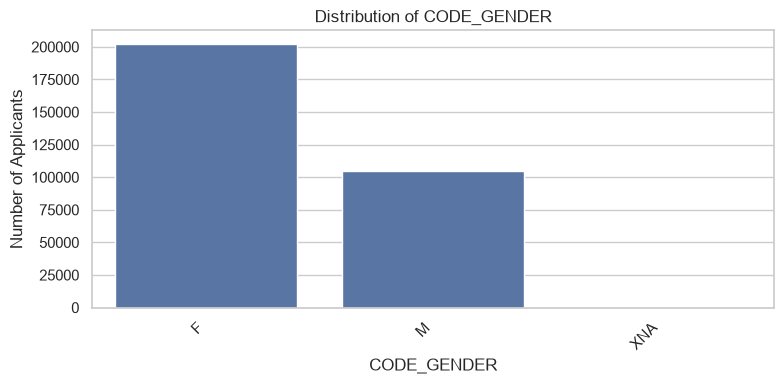

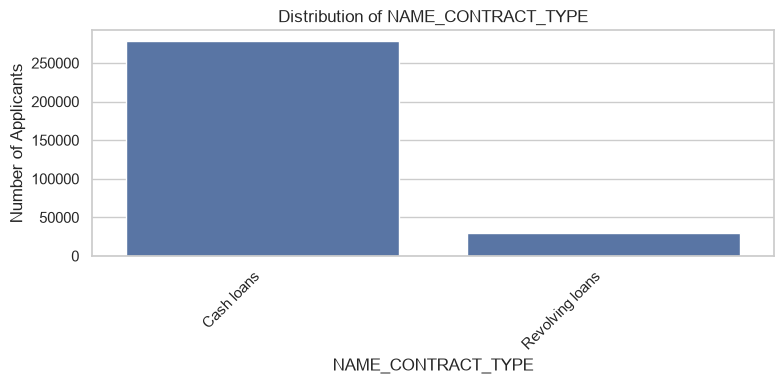

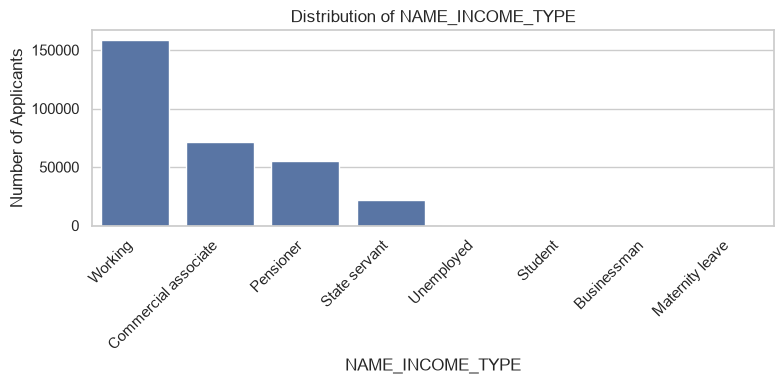

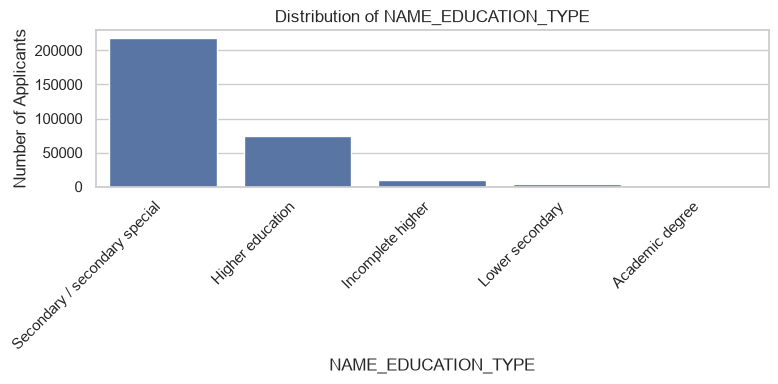

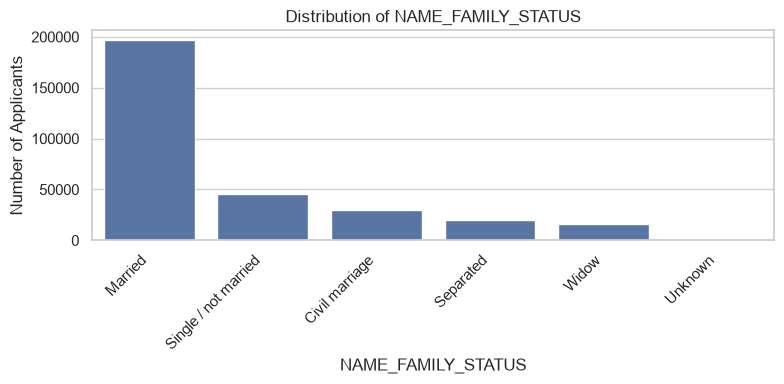

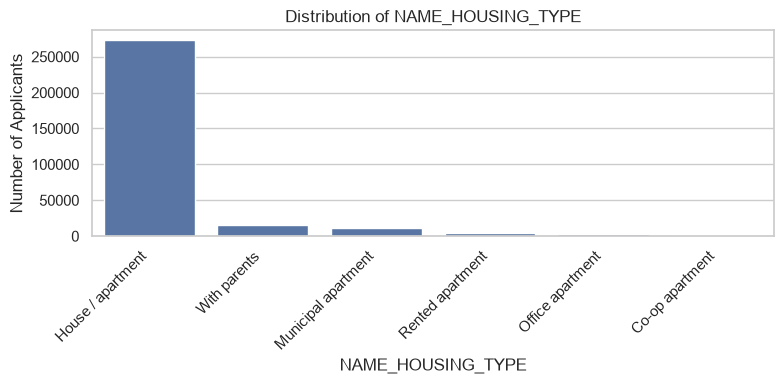

In [17]:
# ============================================================
# Count Plots of Major Categorical Variables
# ============================================================

important_categorical = [
    "CODE_GENDER",
    "NAME_CONTRACT_TYPE",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE"
]

for feature in important_categorical:

    plt.figure(figsize=(8,4))

    order = merged_df[feature].value_counts().index

    sns.countplot(
        data=merged_df,
        x=feature,
        order=order
    )

    plt.xticks(rotation=45, ha="right")

    plt.title(f"Distribution of {feature}")

    plt.xlabel(feature)

    plt.ylabel("Number of Applicants")

    plt.tight_layout()

    plt.show()

# Default Rate by Category

Beyond understanding the frequency of each category, it is important to examine how the credit default rate varies across applicant groups.

For each categorical variable, the average value of the target variable is calculated.

Since:

- TARGET = 0 → No Default
- TARGET = 1 → Default

the mean of TARGET represents the default rate for each category.

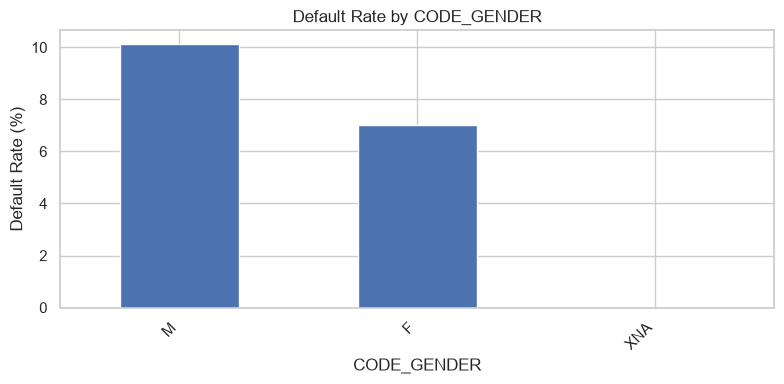

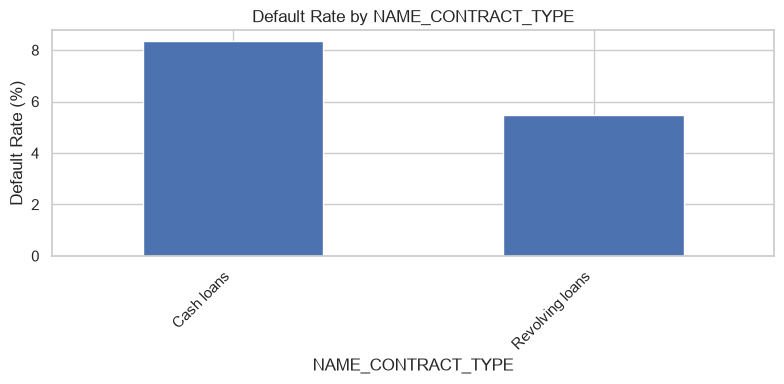

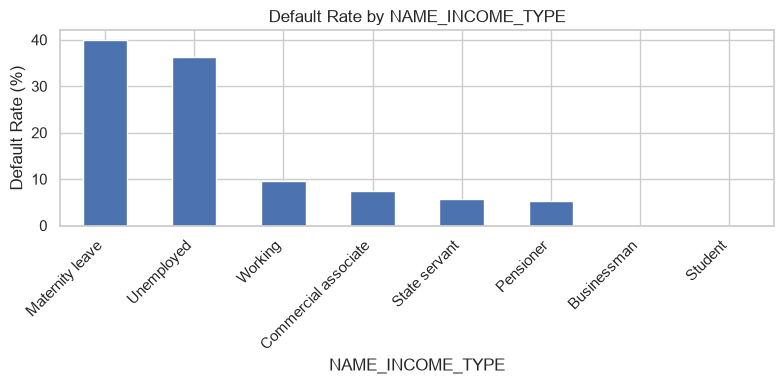

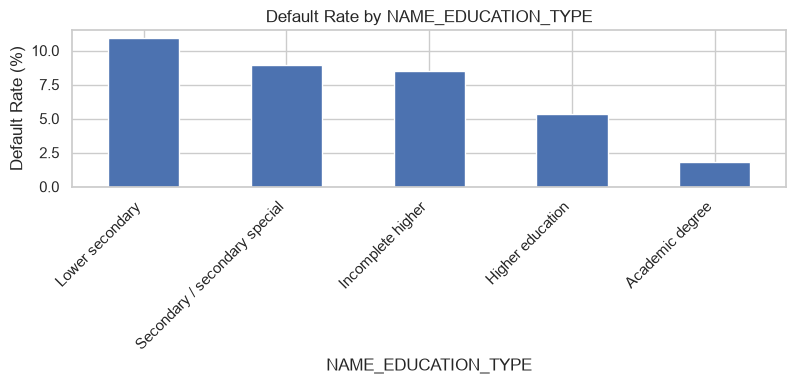

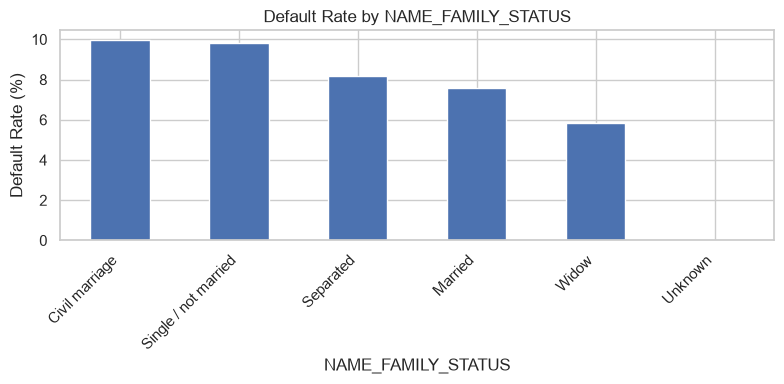

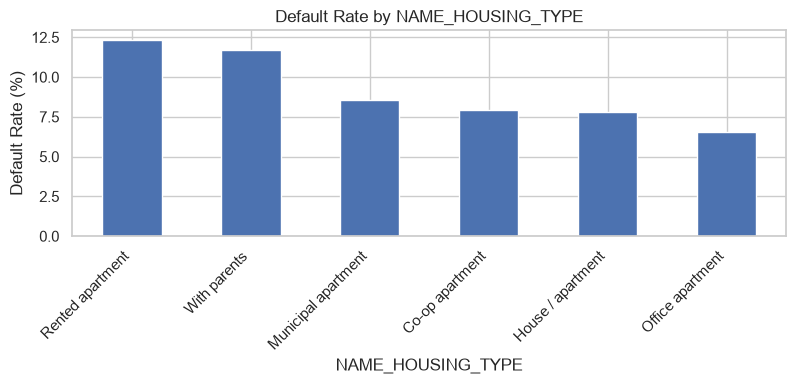

In [18]:
# ============================================================
# Default Rate by Category
# ============================================================

for feature in important_categorical:

    default_rate = (
        merged_df
        .groupby(feature)["TARGET"]
        .mean()
        .sort_values(ascending=False)
        * 100
    )

    plt.figure(figsize=(8,4))

    default_rate.plot(kind="bar")

    plt.title(f"Default Rate by {feature}")

    plt.ylabel("Default Rate (%)")

    plt.xlabel(feature)

    plt.xticks(rotation=45, ha="right")

    plt.tight_layout()

    plt.show()

# Cross-Tabulation of Target Variable

Cross-tabulation provides a numerical summary of the distribution of default and non-default applicants within each category.

The tables presented below support the graphical analysis by reporting applicant counts and percentages for each category.

In [19]:
# ============================================================
# Crosstab Analysis
# ============================================================

for feature in important_categorical:

    print("=" * 80)
    print(feature)

    display(
        pd.crosstab(
            merged_df[feature],
            merged_df["TARGET"],
            normalize="index"
        ).round(3) * 100
    )

CODE_GENDER


TARGET,0,1
CODE_GENDER,,
F,93.0,7.0
M,89.9,10.1
XNA,100.0,0.0


NAME_CONTRACT_TYPE


TARGET,0,1
NAME_CONTRACT_TYPE,,
Cash loans,91.7,8.3
Revolving loans,94.5,5.5


NAME_INCOME_TYPE


TARGET,0,1
NAME_INCOME_TYPE,,
Businessman,100.0,0.0
Commercial associate,92.5,7.5
Maternity leave,60.0,40.0
Pensioner,94.6,5.4
State servant,94.2,5.8
Student,100.0,0.0
Unemployed,63.6,36.4
Working,90.4,9.6


... (2 outputs left out)

NAME_FAMILY_STATUS


TARGET,0,1
NAME_FAMILY_STATUS,,
Civil marriage,90.1,9.9
Married,92.4,7.6
Separated,91.8,8.2
Single / not married,90.2,9.8
Unknown,100.0,0.0
Widow,94.2,5.8


NAME_HOUSING_TYPE


TARGET,0,1
NAME_HOUSING_TYPE,,
Co-op apartment,92.1,7.9
House / apartment,92.2,7.8
Municipal apartment,91.5,8.5
Office apartment,93.4,6.6
Rented apartment,87.7,12.3
With parents,88.3,11.7


# Interpretation of Categorical Analysis

The categorical analysis provides insight into the demographic and socioeconomic composition of the applicant population.

Key observations include:

- The distribution of applicants across demographic categories.
- Differences in default rates among applicant groups.
- Categories associated with relatively higher or lower credit risk.
- Potential relationships between socioeconomic characteristics and repayment behavior.

These findings contribute to understanding applicant profiles and will support feature selection and predictive modeling in subsequent notebooks.

# Correlation Analysis

Correlation analysis measures the strength and direction of the linear relationship between numerical variables.

The objectives of this section are to:

- Identify variables strongly associated with credit default.
- Detect highly correlated predictor variables.
- Understand relationships among key financial variables.
- Support feature selection for subsequent machine learning models.

Pearson's correlation coefficient is used throughout this analysis, with values ranging from **-1** (strong negative correlation) to **+1** (strong positive correlation).

In [20]:
# ============================================================
# Correlation with TARGET
# ============================================================

target_corr = (
    merged_df
    .corr(numeric_only=True)["TARGET"]
    .drop("TARGET")
    .sort_values(ascending=False)
)

target_corr.head(20).to_frame("Correlation with TARGET")

,Correlation with TARGET
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.117815
CC_CNT_DRAWINGS_CURRENT_MAX,0.101389
BUREAU_DAYS_CREDIT_MEAN,0.089729
BUREAU_BB_MONTHS_BALANCE_MIN_MEAN,0.089038
CC_CNT_DRAWINGS_ATM_CURRENT_MAX,0.087636
CC_AMT_BALANCE_MEAN,0.087177
CC_AMT_TOTAL_RECEIVABLE_MEAN,0.086490
CC_AMT_RECIVABLE_MEAN,0.086478
CC_AMT_RECEIVABLE_PRINCIPAL_MEAN,0.086062
CC_CNT_DRAWINGS_CURRENT_MEAN,0.082520


# Features with the Strongest Negative Correlation

Negative correlations indicate variables associated with a lower probability of default.

These features may represent indicators of stronger financial stability or lower credit risk.

In [21]:
target_corr.tail(20).to_frame("Correlation with TARGET")

,Correlation with TARGET
ELEVATORS_AVG,-0.035853
PREV_HOUR_APPR_PROCESS_START_MEAN,-0.035927
REGION_POPULATION_RELATIVE,-0.037227
FLOORSMAX_MODE,-0.038377
FLOORSMAX_MEDI,-0.039157
PREV_RATE_DOWN_PAYMENT_MAX,-0.039178
FLOORSMAX_AVG,-0.039385
AMT_GOODS_PRICE,-0.039623
PREV_DAYS_FIRST_DRAWING_MIN,-0.044522
DAYS_EMPLOYED,-0.044932


# Top Features by Absolute Correlation

To identify the most influential predictors regardless of direction, the absolute value of the correlation coefficient is calculated.

This ranking highlights variables that have the strongest linear relationship with the target variable.

In [22]:
# ============================================================
# Top Absolute Correlations
# ============================================================

top_corr = (
    target_corr.abs()
    .sort_values(ascending=False)
    .head(20)
)

top_corr.to_frame("Absolute Correlation")

,Absolute Correlation
EXT_SOURCE_2,0.160295
EXT_SOURCE_3,0.155892
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.117815
CC_CNT_DRAWINGS_CURRENT_MAX,0.101389
EXT_SOURCE_1,0.098887
BUREAU_DAYS_CREDIT_MEAN,0.089729
BUREAU_BB_MONTHS_BALANCE_MIN_MEAN,0.089038
CC_CNT_DRAWINGS_ATM_CURRENT_MAX,0.087636
CC_AMT_BALANCE_MEAN,0.087177
CC_AMT_TOTAL_RECEIVABLE_MEAN,0.086490


# Correlation Heatmap of Key Features

A heatmap is generated for the variables most strongly associated with the target variable.

This visualization allows us to examine:

- Relationships between important predictors.
- Potential multicollinearity.
- Correlation strength using a color scale.

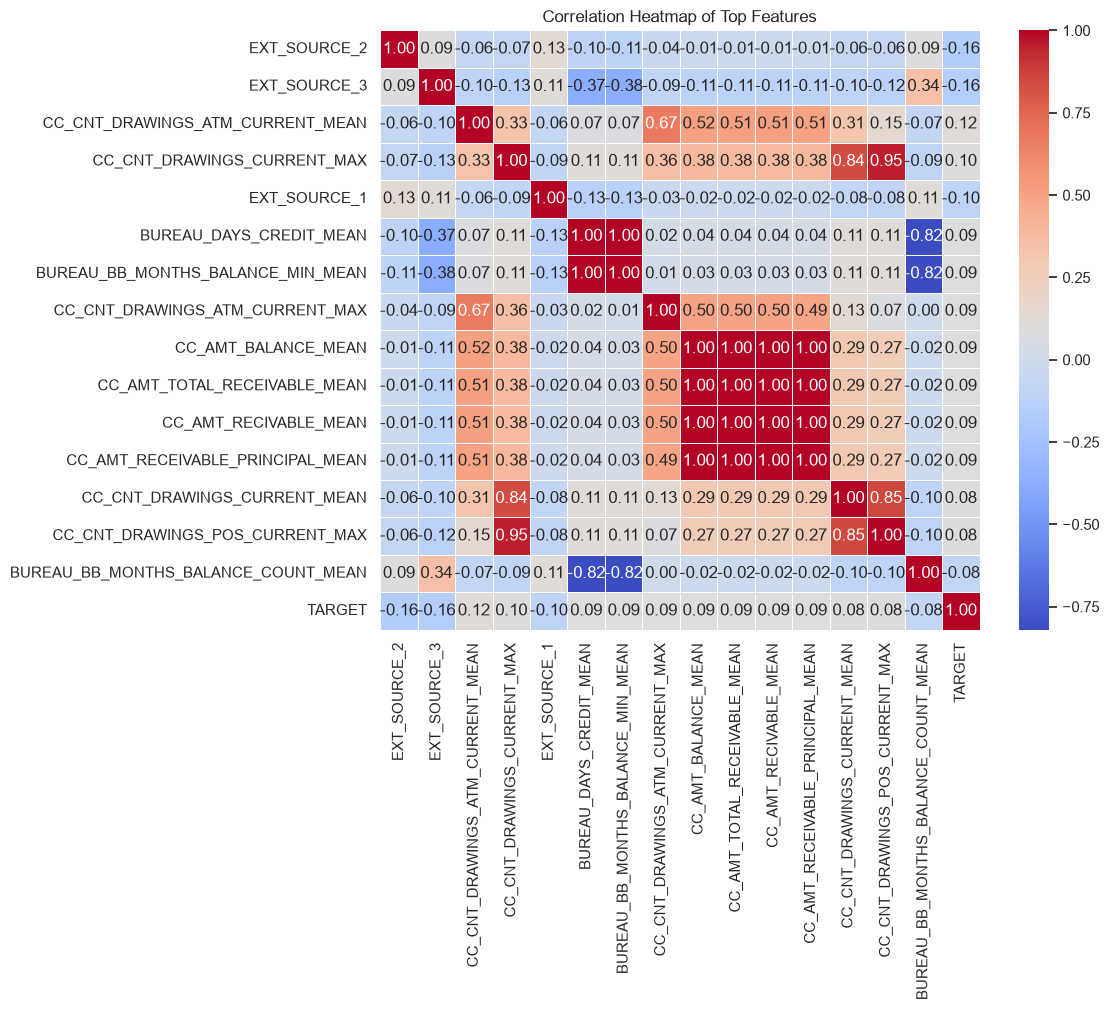

In [23]:
# ============================================================
# Heatmap of Top Correlated Features
# ============================================================

top_features = (
    target_corr.abs()
    .sort_values(ascending=False)
    .head(15)
    .index
    .tolist()
)

top_features.append("TARGET")

corr_matrix = merged_df[top_features].corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Top Features")

plt.tight_layout()

plt.show()

# Highly Correlated Feature Pairs

Highly correlated predictor variables may contain redundant information and contribute to multicollinearity.

The following analysis identifies feature pairs with an absolute correlation coefficient greater than **0.80**.

In [24]:
# ============================================================
# Highly Correlated Feature Pairs
# ============================================================

corr_matrix = merged_df.select_dtypes(include="number").corr().abs()

upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = ["Feature 1", "Feature 2", "Correlation"]

high_corr = high_corr[
    high_corr["Correlation"] > 0.80
].sort_values(
    by="Correlation",
    ascending=False
)

high_corr.head(30)

,Feature 1,Feature 2,Correlation
101968,CC_AMT_RECIVABLE_MIN,CC_AMT_TOTAL_RECEIVABLE_MIN,1.000000
101272,CC_AMT_RECIVABLE_MEAN,CC_AMT_TOTAL_RECEIVABLE_MEAN,0.999999
101620,CC_AMT_RECIVABLE_MAX,CC_AMT_TOTAL_RECEIVABLE_MAX,0.999998
102316,CC_AMT_RECIVABLE_SUM,CC_AMT_TOTAL_RECEIVABLE_SUM,0.999987
81436,INST_DAYS_INSTALMENT_SUM,INST_DAYS_ENTRY_PAYMENT_SUM,0.999961
87388,CC_AMT_BALANCE_MEAN,CC_AMT_RECIVABLE_MEAN,0.999960
87392,CC_AMT_BALANCE_MEAN,CC_AMT_TOTAL_RECEIVABLE_MEAN,0.999955
88432,CC_AMT_BALANCE_SUM,CC_AMT_RECIVABLE_SUM,0.999954
87736,CC_AMT_BALANCE_MAX,CC_AMT_RECIVABLE_MAX,0.999914
87740,CC_AMT_BALANCE_MAX,CC_AMT_TOTAL_RECEIVABLE_MAX,0.999907


# Interpretation of Correlation Analysis

The correlation analysis provides insights into the relationships between applicant characteristics and credit default.

Key findings include:

- Features with the strongest positive correlation to `TARGET` are associated with a higher likelihood of default.
- Features with strong negative correlations indicate characteristics associated with lower credit risk.
- Several aggregated financial variables exhibit strong inter-correlations, reflecting similar historical credit behaviors.
- Highly correlated predictors may introduce multicollinearity, which should be considered during feature engineering and model development.

These findings will guide feature selection, dimensionality reduction using Principal Component Analysis (PCA), and the development of machine learning models in subsequent notebooks.